# 09 · Hiệu năng Spark và 10 · Structured Streaming: biểu đồ

Notebook này **không chạy Spark**. Nó đọc:
- `data/output/perf_report.json` (bước 09, `scripts/09_perf.py`, D17): 1 và 2 worker × dữ liệu 10 / 50 / 100%;
- `data/output/stream_prep_report.json`, `stream_report.json` (bước 10, D18): đáp án theo cửa sổ, kiểm tra 3 kịch bản,
  độ trễ và thông lượng của luồng.

Ảnh lưu vào `docs/images/nb_09_*.png`, `nb_10_*.png`. Dữ liệu hành vi là **mô phỏng**.

Chạy lại: `docker exec -w /home/jovyan/work/notebooks jupyter jupyter nbconvert --to notebook --execute --inplace 09_10_hieu_nang_luong.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nb_style import C, SERIES, load, save, fmt, bar_labels

perf = load("perf_report.json")
prep = load("stream_prep_report.json")
srep = load("stream_report.json")
print(perf["cluster"]["configs"], "·", perf["runs_total"], "lần chạy,", perf["runs_failed"], "lỗi")
for n in perf["notes"][:3]:
    print("-", n)

{'1 worker': '1 executor × 2 core, 2 GB', '2 worker': '2 executor × 2 core, 2 GB mỗi executor'} · 66 lần chạy, 0 lỗi
- Dữ liệu hành vi là MÔ PHỎNG (bước 04). Danh mục món là món thật.
- 1 worker = 1 executor 2 core, 2 GB; 2 worker = 2 executor, tổng 4 core, 4 GB. Đổi từ 2 xuống 1 worker giảm CẢ số core LẪN bộ nhớ executor, nên speedup là của cụm 2 nút so với 1 nút, không tách riêng ảnh hưởng của core và bộ nhớ.
- Mọi container chạy trên cùng một máy (máy ảo Docker): shuffle giữa 2 worker đi qua mạng ảo của Docker, không phải mạng thật; datanode là container riêng nên cả 1 lẫn 2 worker đều không có data locality.


## 1. Speedup 2 worker so với 1 worker, theo mức dữ liệu
Speedup = thời gian 1 worker / thời gian 2 worker (trung vị khi chạy nhiều lần). 1 = không nhanh hơn, 2 = lý tưởng.
1 worker = 1 executor 2 core 2 GB; 2 worker = 2 executor, tổng 4 core 4 GB.

da ghi docs/images/nb_09_speedup_theo_muc.png


level_pct,10,50,100
step,,,
04 Sinh hành vi,1.03,2.19,1.71
05 Phân tích hành vi,0.77,1.22,1.21
06b ALS + baseline,1.01,1.56,1.32
Chuỗi 04 → 06f,0.88,1.59,1.38


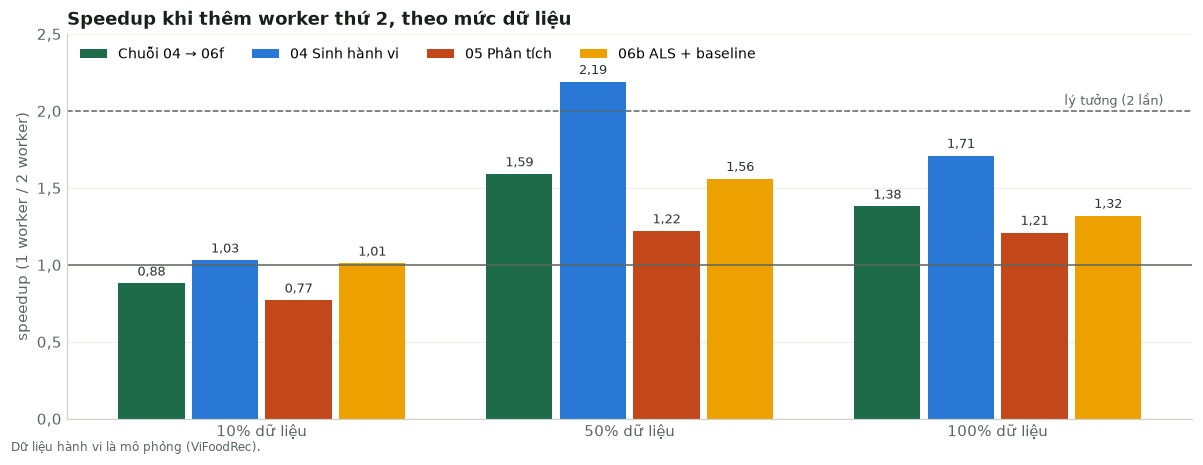

In [2]:
sb = pd.DataFrame(perf["speedup_by_scale"])
keys = ["chain", "04", "05", "06b"]
names = {"chain": "Chuỗi 04 → 06f", "04": "04 Sinh hành vi", "05": "05 Phân tích", "06b": "06b ALS + baseline"}
levels = [10, 50, 100]
fig, ax = plt.subplots(figsize=(11, 4.2))
w = 0.2
x = np.arange(len(levels))
for i, k in enumerate(keys):
    d = sb[sb.key == k].set_index("level_pct").reindex(levels)
    b = ax.bar(x + (i - 1.5) * w, d.speedup, width=w - 0.02, color=SERIES[i], label=names[k])
    bar_labels(ax, b, nd=2)
ax.axhline(1, color=C["muted"], lw=1)
ax.axhline(2, color=C["muted"], lw=1, ls="--")
ax.annotate("lý tưởng (2 lần)", (x[-1] + 0.45, 2), xytext=(0, 4), textcoords="offset points", ha="right", fontsize=8.5,
            color=C["muted"])
ax.set_xticks(x, [f"{l}% dữ liệu" for l in levels])
ax.set_ylabel("speedup (1 worker / 2 worker)"); ax.set_ylim(0, 2.5)
ax.legend(ncol=4, loc="upper left")
ax.set_title("Speedup khi thêm worker thứ 2, theo mức dữ liệu")
fig.tight_layout()
save(fig, "09_speedup_theo_muc")
sb.pivot(index="step", columns="level_pct", values="speedup")

## 2. Thời gian cả chuỗi 04 → 06f

da ghi docs/images/nb_09_thoi_gian_chuoi.png


,level_pct,workers,total_s,ratio_vs_10pct
0,10,1,473.1,1.00
1,10,2,535.8,1.00
2,50,1,1658.4,3.51
3,50,2,1044.8,1.95
4,100,1,2345.2,4.96
5,100,2,1702.9,3.18


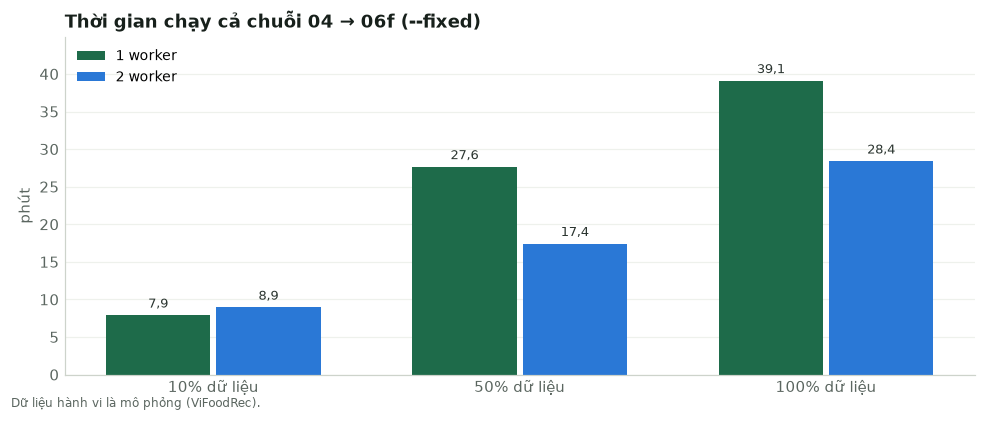

In [3]:
ct = pd.DataFrame(perf["chain_totals"])
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, wk in enumerate([1, 2]):
    d = ct[ct.workers == wk].set_index("level_pct").reindex(levels)
    b = ax.bar(x + (i - 0.5) * 0.36, d.total_s / 60, width=0.34, color=SERIES[i], label=f"{wk} worker")
    bar_labels(ax, b, nd=1)
ax.set_xticks(x, [f"{l}% dữ liệu" for l in levels]); ax.set_ylabel("phút")
ax.set_ylim(0, ct.total_s.max() / 60 * 1.15)
ax.legend(loc="upper left")
ax.set_title("Thời gian chạy cả chuỗi 04 → 06f (--fixed)")
fig.tight_layout()
save(fig, "09_thoi_gian_chuoi")
ct[["level_pct", "workers", "total_s", "ratio_vs_10pct"]]

## 3. Tăng dữ liệu (2 worker): thời gian tăng chậm hơn lượng dữ liệu
Tỷ lệ thời gian so với mức 10%. Dữ liệu tăng 5 và 10 lần (đường chéo); job có phần cố định (khởi động, đọc danh mục)
nên tăng ít hơn. 04 gần tuyến tính nhất vì phần sinh sự kiện tỷ lệ với số user.

da ghi docs/images/nb_09_mo_rong_du_lieu.png


,job,step,t_10_s,t_50_s,t_100_s,ratio_50_10,ratio_100_10
0,04,04 Sinh hành vi,97.4,275.2,527.5,2.83,5.42
1,05,05 Phân tích hành vi,68.6,90.8,110.3,1.32,1.61
2,06a,06a Chia dữ liệu,47.5,73.8,103.1,1.55,2.17
3,06b,06b ALS + baseline,119.5,331.4,599.3,2.77,5.02
4,06c,06c Content,84.0,115.0,158.7,1.37,1.89
5,06d,06d FP-Growth,34.9,38.1,42.6,1.09,1.22
6,06e,06e K-means,35.6,43.0,52.4,1.21,1.47
7,06f,06f Hybrid,48.3,77.5,109.0,1.60,2.26


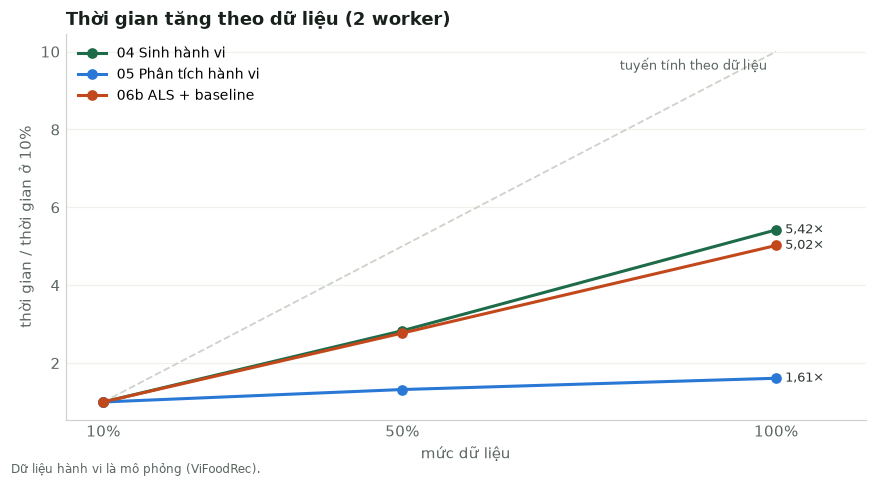

In [4]:
sc = pd.DataFrame(perf["scaling_2w"])
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot([10, 50, 100], [1, 5, 10], color=C["line"], ls="--", lw=1.2)
ax.annotate("tuyến tính theo dữ liệu", (100, 10), xytext=(-6, -4), textcoords="offset points", ha="right", va="top",
            fontsize=8.5, color=C["muted"])
for i, job in enumerate(["04", "05", "06b"]):
    r = sc[sc.job == job].iloc[0]
    ys = [1, r.ratio_50_10, r.ratio_100_10]
    ax.plot([10, 50, 100], ys, marker="o", color=SERIES[i], label=r.step)
    ax.annotate(f"{fmt(ys[-1], 2)}×", (100, ys[-1]), xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=8.5, color=C["ink2"])
ax.set_xticks([10, 50, 100], ["10%", "50%", "100%"]); ax.set_xlim(5, 112)
ax.set_ylabel("thời gian / thời gian ở 10%"); ax.set_xlabel("mức dữ liệu")
ax.legend(loc="upper left")
ax.set_title("Thời gian tăng theo dữ liệu (2 worker)")
fig.tight_layout()
save(fig, "09_mo_rong_du_lieu")
sc

## 4. Bước 04 chạy lặp lại: độ ổn định của phép đo
Mỗi chấm là một lần chạy (ms cho mỗi user mô phỏng = thời gian / số user). 04 ở 50% và 100% với 1 worker chạy 3 lần.
Ở 100% / 1 worker, lần r2 (1.230,1 giây) chạy trùng lúc máy làm việc khác; r1 và r3 khớp nhau (864,4 và 900,4 giây).

da ghi docs/images/nb_09_lap_lai_04.png


,level_pct,workers,n_runs,runs_s,median_s
0,10.0,1,1,[100.7],100.7
1,10.0,2,1,[97.4],97.4
16,50.0,1,3,"[575.8, 604.0, 631.8]",604.0
17,50.0,2,1,[275.2],275.2
32,100.0,1,3,"[864.4, 900.4, 1230.1]",900.4
33,100.0,2,1,[527.5],527.5


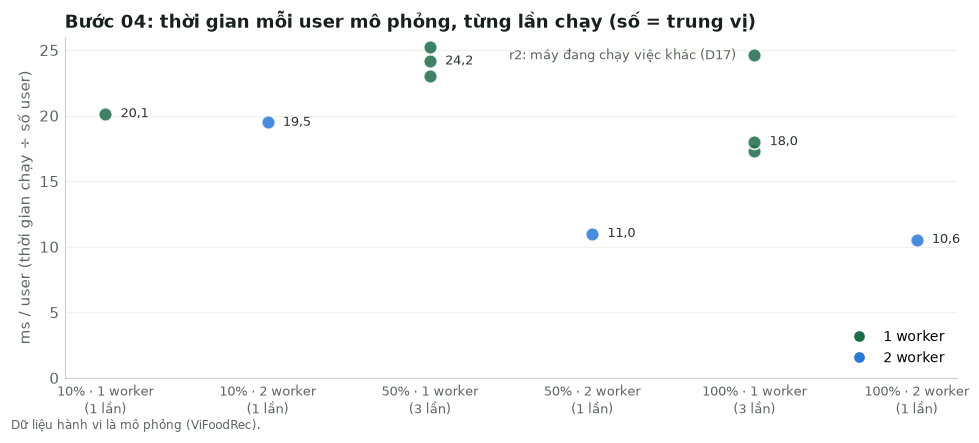

In [5]:
rows = pd.DataFrame(perf["rows"])
r04 = rows[rows.job == "04"]
users = {k: v["users"] for k, v in perf["data"].items()}
fig, ax = plt.subplots(figsize=(9, 4))
ticks = []
for j, (lv, wk) in enumerate([(l, wk) for l in ["s010", "s050", "s100"] for wk in (1, 2)]):
    r = r04[(r04.level == lv) & (r04.workers == wk)]
    if r.empty:
        continue
    r = r.iloc[0]
    ms = [t * 1000 / users[lv] for t in r.runs_s]
    ax.plot([j] * len(ms), ms, "o", ms=9, color=SERIES[wk - 1], alpha=0.85, mec="white", mew=1.2)
    ax.annotate(fmt(np.median(ms), 1), (j, np.median(ms)), xytext=(10, 0), textcoords="offset points", va="center",
                fontsize=8.5, color=C["ink2"])
    ticks.append((j, f"{int(r.level_pct)}% · {wk} worker\n({len(ms)} lần)"))
    if lv == "s100" and wk == 1 and len(ms) >= 2:
        # lan r2 chay trung luc may lam viec khac (chay notebook, lenh HDFS), xem D17
        # runs_s da sap xep tang dan; r2 la lan cham nhat
        ax.annotate("r2: máy đang chạy việc khác (D17)", (j, max(ms)), xytext=(-12, 0), textcoords="offset points",
                    ha="right", va="center", fontsize=8.5, color=C["muted"])
ax.set_xticks([t[0] for t in ticks], [t[1] for t in ticks], fontsize=8.5)
ax.set_ylabel("ms / user (thời gian chạy ÷ số user)"); ax.set_ylim(0, None)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=SERIES[0], label="1 worker"),
                   Line2D([], [], marker="o", ls="", color=SERIES[1], label="2 worker")], loc="lower right")
ax.set_title("Bước 04: thời gian mỗi user mô phỏng, từng lần chạy (số = trung vị)")
fig.tight_layout()
save(fig, "09_lap_lai_04")
r04[["level_pct", "workers", "n_runs", "runs_s", "median_s"]]

## 5. Structured Streaming: lượt nấu theo cửa sổ (đáp án batch)
Cửa sổ 60 phút trượt 15 phút, CN 27/09/2026 06:00–24:00, toàn quốc. Đáp án tính bằng batch trên cùng hàm tổng hợp
với luồng (`stream_common.aggregate`); kịch bản s1, s2 của 10c khớp tuyệt đối 205.920 ô.

da ghi docs/images/nb_10_cua_so_dap_an.png


/tmp/ipykernel_61374/1220963564.py:3: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ws["end"] = pd.to_datetime(ws.ws) + pd.Timedelta(minutes=60)


'/home/jovyan/work/docs/images/nb_10_cua_so_dap_an.png'

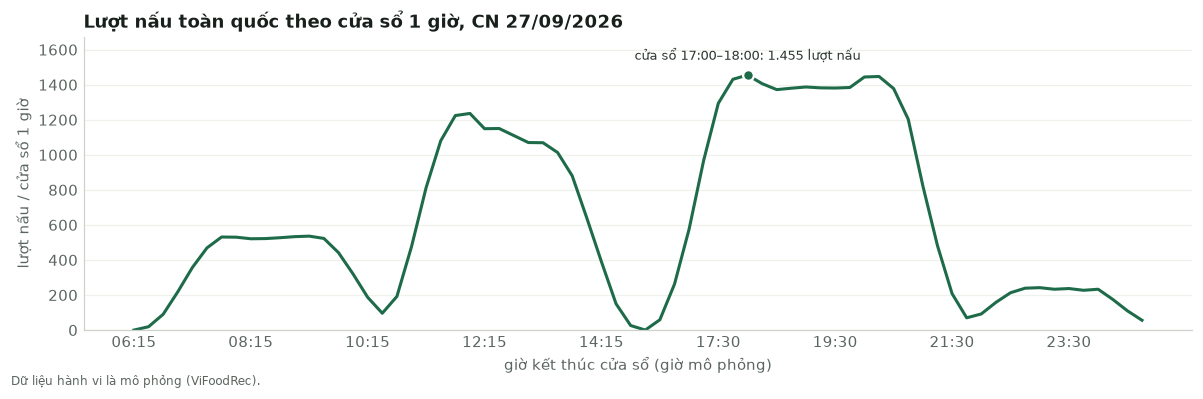

In [6]:
cw = prep["2026-09-27"]["expected"]["cooks_per_window"]
ws = pd.DataFrame([(k.split("|")[0], v) for k, v in cw.items() if k.endswith("|all")], columns=["ws", "cooks"])
ws["end"] = pd.to_datetime(ws.ws) + pd.Timedelta(minutes=60)
fig, ax = plt.subplots(figsize=(11, 3.6))
lab = [("24:00" if e.hour == 0 and e.minute == 0 else e.strftime("%H:%M")) for e in ws.end]
ax.plot(range(len(ws)), ws.cooks, color=C["herb"])
pk = ws.cooks.idxmax()
ax.plot([pk], [ws.cooks[pk]], "o", color=C["herb"], ms=7, mec="white", mew=1.5)
ax.annotate(f"cửa sổ {ws.ws[pk][11:16]}–{lab[pk]}: {fmt(ws.cooks[pk])} lượt nấu", (pk, ws.cooks[pk]), xytext=(0, 10),
            textcoords="offset points", fontsize=8.5, color=C["ink2"], ha="center")
step = 8
ax.set_xticks(range(0, len(ws), step), lab[::step])
ax.set_xlabel("giờ kết thúc cửa sổ (giờ mô phỏng)"); ax.set_ylabel("lượt nấu / cửa sổ 1 giờ")
ax.set_ylim(0, ws.cooks.max() * 1.15)
ax.set_title("Lượt nấu toàn quốc theo cửa sổ 1 giờ, CN 27/09/2026")
fig.tight_layout()
save(fig, "10_cua_so_dap_an")

## 6. Kiểm tra đúng (10c): 3 kịch bản đến trễ

In [7]:
ck = srep["checks"]["scenarios"]
tb = pd.DataFrame([{"Kịch bản": k, "Mô tả": v["desc"], "Ô lệch": v["cells_differ"], "Doc lệch": v["docs_differ"],
                    "Trễ ≤ 8 phút": v["late_within"], "Gửi lặp": v["duplicates_sent"],
                    "Giữ quá watermark": v["held_beyond_watermark"],
                    "Bỏ theo watermark": sum(v["dropped_by_watermark"].values()),
                    "Đạt": "đạt" if v["pass"] else "không"} for k, v in ck.items()])
tb

,Kịch bản,Mô tả,Ô lệch,Doc lệch,Trễ ≤ 8 phút,Gửi lặp,Giữ quá watermark,Bỏ theo watermark,Đạt
0,s1,"không trễ, không gửi lặp",0,0,0,0,0,0,đạt
1,s2,"3% trễ 1–8 phút, 0,2% gửi lặp",0,0,2757,180,0,0,đạt
2,s3,"như s2, thêm 0,3% bị giữ 20–40 phút (quá water...",957,254,2795,173,264,255,đạt


## 7. Độ trễ của luồng (10d)
Độ trễ = sự kiện mới nhất trong batch, từ lúc replayer ghi file đến lúc ghi MongoDB xong (hoặc lúc API E25 trả về batch đó).
Tốc độ 60: trigger 5 giây; 300 và 1.200: trigger 1 giây.

da ghi docs/images/nb_10_do_tre.png


,tốc độ 60,tốc độ 300,tốc độ 1.200
batch p50 (giây),1.278,1.815,2.591
batch vượt trigger,1.000,31.000,17.000
batch có dữ liệu,38.000,33.000,17.000
xử lý / giây p50,659.500,854.400,1162.300


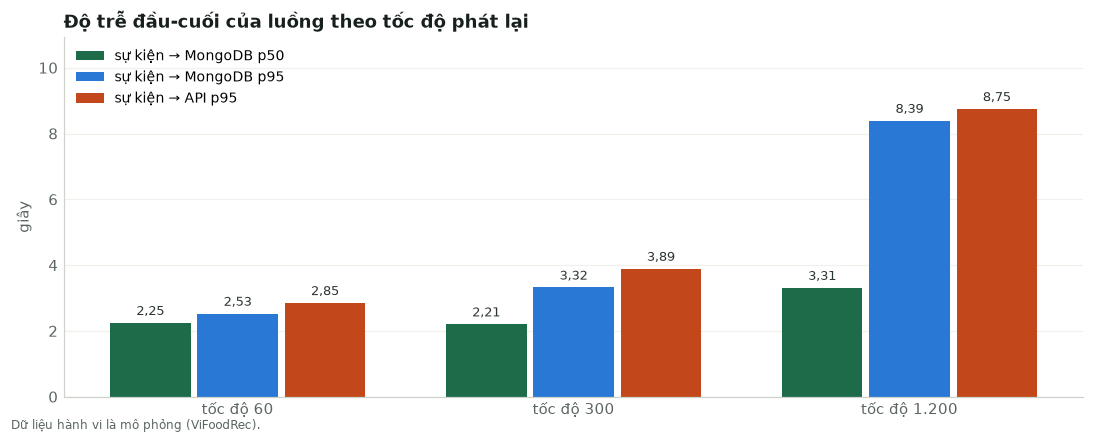

In [8]:
b = srep["bench"]
runs = [("lat60", "tốc độ 60"), ("lat300", "tốc độ 300"), ("lat1200", "tốc độ 1.200")]
fig, ax = plt.subplots(figsize=(10, 4))
metrics = [("latency_event_to_mongo_s", "p50", "sự kiện → MongoDB p50"), ("latency_event_to_mongo_s", "p95", "sự kiện → MongoDB p95"),
           ("latency_event_to_api_s", "p95", "sự kiện → API p95")]
x = np.arange(len(runs)); w = 0.26
for i, (m, q, label) in enumerate(metrics):
    vals = [b[r][m][q] for r, _ in runs]
    bars = ax.bar(x + (i - 1) * w, vals, width=w - 0.02, color=SERIES[i], label=label)
    bar_labels(ax, bars, nd=2)
ax.set_xticks(x, [n for _, n in runs]); ax.set_ylabel("giây")
ax.set_ylim(0, max(b[r]["latency_event_to_api_s"]["p95"] for r, _ in runs) * 1.25)
ax.legend(loc="upper left")
ax.set_title("Độ trễ đầu-cuối của luồng theo tốc độ phát lại")
fig.tight_layout()
save(fig, "10_do_tre")
pd.DataFrame({n: {"batch p50 (giây)": b[r]["batch_duration_s"]["p50"], "batch vượt trigger": b[r]["batches_over_trigger"],
                  "batch có dữ liệu": b[r]["batches_with_data"], "xử lý / giây p50": b[r]["processed_rows_per_s"]["p50"]}
              for r, n in runs})

## 8. Thông lượng và nút thắt (10d, 7 ngày 21–27/09/2026, ghi sẵn 15 file, 2 file mỗi trigger)
Thời gian batch chia thành: Spark tính micro-batch và gom kết quả về driver (collect); ghi MongoDB phần (a) upsert
`trending_cells`; phần (b) đọc lại ô, tính top 20 + "tăng nhanh", ghi `trending`; phần còn lại (lập kế hoạch, commit offset…).

da ghi docs/images/nb_10_thong_luong.png


,collect,(a) upsert ô,(b) top 20 + trending,ghi MongoDB (chưa tách),còn lại,dòng / giây
cấu hình,,,,,,
2 core,20.5,36.6,10.6,None,6.0,6645
4 core,16.5,34.9,9.6,None,5.3,7394


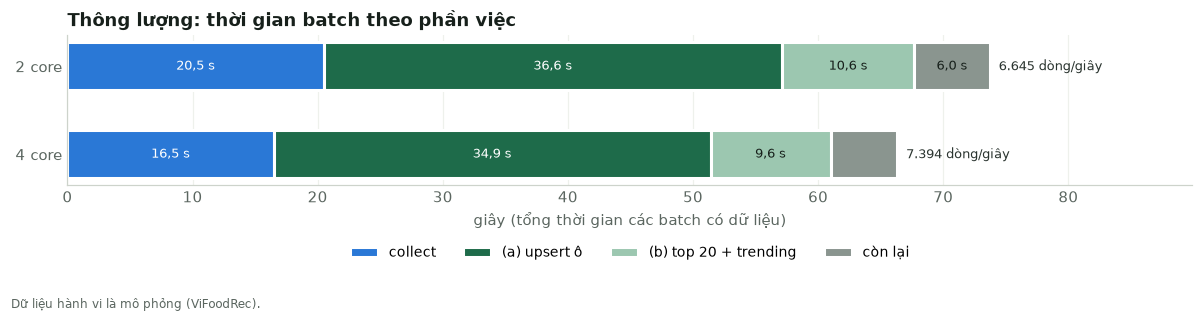

In [9]:
parts = []
for r, n in [("thr_c2", "2 core"), ("thr_c4", "4 core")]:
    s = b[r]["sink_breakdown_s"]
    a = s.get("mongo_cells_upsert"); bb = s.get("mongo_trending")
    rest = s["trigger_total"] - s["collect"] - s["mongo"]
    parts.append({"cấu hình": n, "collect": s["collect"], "(a) upsert ô": a, "(b) top 20 + trending": bb,
                  "ghi MongoDB (chưa tách)": None if a is not None else s["mongo"], "còn lại": rest,
                  "dòng / giây": b[r]["rows_per_s_overall"]})
pt = pd.DataFrame(parts).set_index("cấu hình")
cols = [c for c in ["collect", "(a) upsert ô", "(b) top 20 + trending", "ghi MongoDB (chưa tách)", "còn lại"] if pt[c].notna().all()]
colors = {"collect": C["blue"], "(a) upsert ô": C["herb"], "(b) top 20 + trending": C["herb_mid"],
          "ghi MongoDB (chưa tách)": C["herb"], "còn lại": C["neutral"]}
fig, ax = plt.subplots(figsize=(11, 2.9))
left = np.zeros(len(pt))
for c in cols:
    bars = ax.barh(pt.index, pt[c], left=left, color=colors[c], height=0.55, edgecolor="white", linewidth=2, label=c)
    for rect, v, l0 in zip(bars, pt[c], left):
        if v >= 6:
            ax.text(l0 + v / 2, rect.get_y() + rect.get_height() / 2, f"{fmt(v, 1)} s", ha="center", va="center",
                    fontsize=8.5, color="white" if c in ("collect", "(a) upsert ô", "ghi MongoDB (chưa tách)") else C["ink"])
    left += pt[c].values
for i, (n, r) in enumerate(pt.iterrows()):
    ax.annotate(f"{fmt(r['dòng / giây'])} dòng/giây", (left[i], i), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=C["ink2"])
ax.invert_yaxis(); ax.set_xlim(0, left.max() * 1.22); ax.set_xlabel("giây (tổng thời gian các batch có dữ liệu)")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.legend(ncol=len(cols), loc="upper center", bbox_to_anchor=(0.5, -0.32))
ax.set_title("Thông lượng: thời gian batch theo phần việc")
fig.tight_layout()
save(fig, "10_thong_luong")
pt